# Agrupamento com K-means: da intuição ao código

Notebook complementar à apresentação **Kmeans_Didatico_Final.pptx**, adaptada do material do Prof. Aldebaro Klautau (UFPA/LASSE).

Vamos seguir o fluxo dos slides: entender os dados, executar uma rodada à mão, conferir com o scikit-learn e explorar decisões que afetam o resultado. Os títulos indicam os slides correspondentes.

**Ao terminar, você deverá conseguir:**
- distinguir amostras, atributos, rótulos e centroides;
- atribuir amostras ao centroide mais próximo e recalcular as médias;
- usar `fit_predict`, `predict`, `cluster_centers_` e `inertia_`;
- avaliar escala, inicialização, cotovelo e silhouette sem tratar métricas como respostas definitivas.

**Como usar:** abra no Jupyter, VS Code ou Google Colab e execute de cima para baixo. O notebook não precisa baixar bases de dados. Os gráficos usam a paleta azul, verde, laranja e cinza dos slides. As saídas já estão incluídas para leitura sem execução.



## Preparação do ambiente

Usaremos NumPy, pandas, Matplotlib e scikit-learn. Se algum pacote estiver ausente, descomente a linha abaixo em uma célula do Jupyter/Colab e execute. Em seguida, reinicie o kernel se o ambiente solicitar.


In [1]:
# %pip install numpy pandas matplotlib scikit-learn


In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import sklearn
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import silhouette_score, silhouette_samples

SEMENTE = 42
AZUL, VERDE, LARANJA, CINZA = '#4285F4', '#0F9D58', '#E59000', '#F2F2F2'
PALETA = [AZUL, VERDE, LARANJA, '#76A7FA', '#33B679', '#8B5A2B', '#707070', '#173E7A']
plt.rcParams.update({'figure.figsize': (8, 5), 'font.size': 11,
                     'axes.titlesize': 14, 'axes.grid': True,
                     'grid.alpha': 0.2, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)


Python: 3.12.14
scikit-learn: 1.8.0


## 1. Aprendizado não supervisionado 

No agrupamento, recebemos atributos das amostras, mas **não entregamos ao algoritmo o grupo correto de cada uma**. O algoritmo procura uma organização com base na semelhança entre elas.

| Tarefa | Ideia | Exemplo |
|---|---|---|
| Agrupamento | Reunir observações parecidas | Clientes com hábitos de compra semelhantes |
| Detecção de anomalias | Encontrar observações incomuns | Um sensor com consumo fora do padrão |
| Estimação de densidade | Descrever onde os dados se concentram | Regiões frequentes e raras de operação |

O foco deste notebook é o **K-means**. Ele representa cada grupo por um **centroide**, calculado como a média das amostras desse grupo. K é o número de grupos escolhido antes do ajuste.

Os números dos grupos (0, 1, 2...) são identificadores. Grupo 1 não é “melhor” que grupo 0, e a numeração pode mudar entre execuções.


## 2. Amostras e atributos 

Vamos usar exatamente os quatro pontos da apresentação. Cada linha de `X_pequeno` é uma amostra; cada coluna é um atributo. As letras A, B, C e D são identificadores e ficam fora da matriz numérica.

Neste exemplo artificial, os dois atributos têm escalas comparáveis. Usaremos os valores originais para acompanhar as contas dos slides.


In [3]:
X_pequeno = np.array([[1, 1], [1, 3], [5, 5], [7, 5]], dtype=float)
nomes = np.array(['A', 'B', 'C', 'D'])
dados_pequenos = pd.DataFrame(X_pequeno, index=nomes, columns=['x1', 'x2'])
dados_pequenos.index.name = 'Amostra'
print('Formato:', X_pequeno.shape, '= 4 amostras e 2 atributos')
display(dados_pequenos)


Formato: (4, 2) = 4 amostras e 2 atributos


,x1,x2
Amostra,,
A,1.0,1.0
B,1.0,3.0
C,5.0,5.0
D,7.0,5.0


A função abaixo será reutilizada para desenhar pontos e centroides. Você pode executar a célula e seguir adiante; ela apenas evita repetir código de visualização.


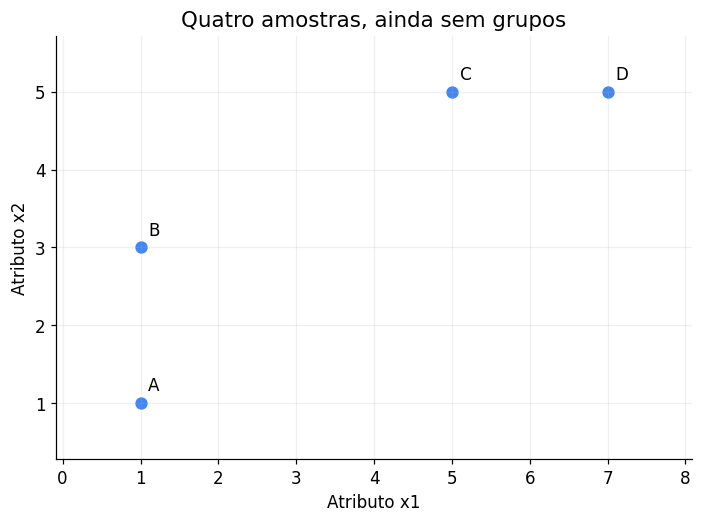

In [4]:
def desenhar_grupos(X, rotulos=None, centros=None, titulo='', ax=None, nomes=None):
    if ax is None:
        _, ax = plt.subplots()
    if rotulos is None:
        ax.scatter(X[:, 0], X[:, 1], color=AZUL, s=50)
    else:
        for grupo in np.unique(rotulos):
            pontos = X[rotulos == grupo]
            ax.scatter(pontos[:, 0], pontos[:, 1], s=38,
                       color=PALETA[int(grupo) % len(PALETA)], label=f'Grupo {grupo}')
    if centros is not None:
        ax.scatter(centros[:, 0], centros[:, 1], marker='X', s=190,
                   c=LARANJA, edgecolors='black', linewidths=0.8, label='Centroides', zorder=5)
        for j, centro in enumerate(centros):
            ax.annotate(f'μ{j}', centro, xytext=(9, -15), textcoords='offset points')
    if nomes is not None:
        for nome, ponto in zip(nomes, X):
            ax.annotate(nome, ponto, xytext=(5, 8), textcoords='offset points')
    ax.set(xlabel='Atributo x1', ylabel='Atributo x2', title=titulo)
    ax.set_aspect('equal', adjustable='box')
    ax.margins(0.18)
    if rotulos is not None or centros is not None:
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8) if len(X) > 20 else ax.legend(loc='best', fontsize=9)
    return ax

desenhar_grupos(X_pequeno, nomes=nomes, titulo='Quatro amostras, ainda sem grupos')
plt.show()


## 3. A escala dos atributos 

Uma distância depende dos valores e das unidades de cada atributo. Compare clientes descritos por compras por mês e gasto mensal: uma variação de R$ 50 pode dominar uma variação de 1 compra.

Na distância euclidiana ao quadrado, somamos as diferenças ao quadrado de cada atributo. Vamos separar essas contribuições.


In [5]:
clientes = pd.DataFrame({'compras_mes': [2, 3, 8],
                         'gasto_mensal': [200, 250, 210]}, index=['A', 'B', 'C'])
display(clientes)
diferenca_AB = clientes.loc['A'] - clientes.loc['B']
display(pd.DataFrame({'diferença A − B': diferenca_AB,
                      'contribuição para distância²': diferenca_AB**2}))
print('Distância² entre A e B:', float((diferenca_AB**2).sum()))


Distância² entre A e B: 2501.0


,compras_mes,gasto_mensal
A,2,200
B,3,250
C,8,210


,diferença A − B,contribuição para distância²
compras_mes,-1,1
gasto_mensal,-50,2500


`StandardScaler` transforma cada coluna para ter média aproximadamente zero e desvio-padrão unitário (na convenção usada pelo estimador). Não limita os valores ao intervalo [0, 1].

**Entrada:** matriz de atributos. **Saída:** matriz com o mesmo formato e atributos padronizados. A transformação deve fazer sentido para o problema: padronizar não determina automaticamente a importância correta dos atributos.


In [6]:
escalador_clientes = StandardScaler()
clientes_padronizados = escalador_clientes.fit_transform(clientes)
display(pd.DataFrame(clientes_padronizados, index=clientes.index,
                     columns=clientes.columns).round(3))
print('Médias:', clientes_padronizados.mean(axis=0).round(6))
print('Desvios-padrão:', clientes_padronizados.std(axis=0).round(6))


Médias: [ 0. -0.]
Desvios-padrão: [1. 1.]


,compras_mes,gasto_mensal
A,-0.889,-0.926
B,-0.508,1.389
C,1.397,-0.463


## 4. Inicialização da rodada

Vamos fixar **K = 2** e os centroides iniciais **μ₀ = (1, 1)** e **μ₁ = (5, 5)**. Eles coincidem com A e C para facilitar as contas.

Uma rodada terá duas etapas:
1. atribuir cada amostra ao centroide mais próximo;
2. atualizar cada centroide para a média das amostras atribuídas a ele.

A escolha manual aqui serve à explicação. Em aplicações, podemos usar `k-means++` para inicializar.


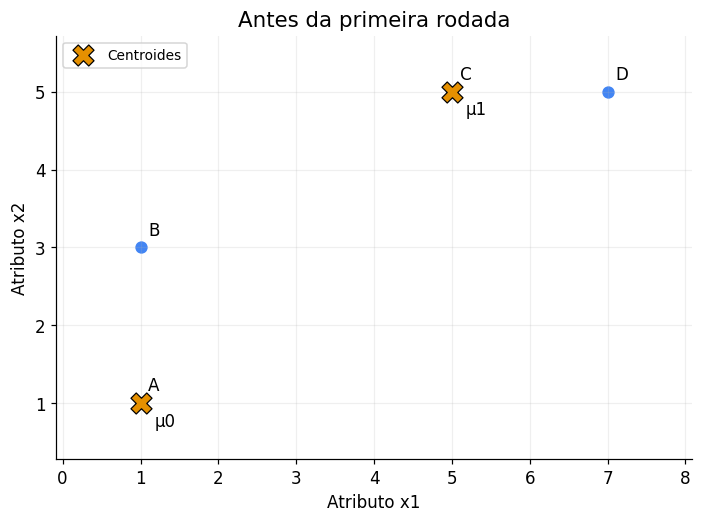

In [7]:
centros_iniciais = np.array([[1, 1], [5, 5]], dtype=float)
desenhar_grupos(X_pequeno, centros=centros_iniciais, nomes=nomes,
                titulo='Antes da primeira rodada')
plt.show()


## 5. Passo 1: atribuição 

Para B = (1, 3), a distância² até μ₀ é `(1−1)² + (3−1)² = 4`; até μ₁, é `(1−5)² + (3−5)² = 20`. Portanto, B vai para o grupo 0.

Podemos comparar distâncias ao quadrado sem tirar a raiz: o centroide mais próximo será o mesmo. A implementação com laços abaixo prioriza clareza.


In [8]:
def distancias_quadradas(X, centros):
    """Retorna uma matriz: linhas = amostras; colunas = centroides."""
    distancias = np.zeros((len(X), len(centros)))
    for i, amostra in enumerate(X):
        for j, centro in enumerate(centros):
            diferenca = amostra - centro
            distancias[i, j] = np.sum(diferenca**2)
    return distancias

D_inicial = distancias_quadradas(X_pequeno, centros_iniciais)
rotulos_rodada = np.argmin(D_inicial, axis=1)
tabela_atribuicao = pd.DataFrame(D_inicial, index=nomes,
                                 columns=['d² até μ0', 'd² até μ1'])
tabela_atribuicao['Grupo'] = rotulos_rodada
display(tabela_atribuicao)


,d² até μ0,d² até μ1,Grupo
A,0.0,32.0,0
B,4.0,20.0,0
C,32.0,0.0,1
D,52.0,4.0,1


`np.argmin(..., axis=1)` retorna, para cada linha, a coluna que contém a menor distância. A saída `[0, 0, 1, 1]` significa: A e B no grupo 0; C e D no grupo 1. Em um empate, esta implementação escolhe o primeiro mínimo.


## 6. Passo 2: atualização 

Calculamos a média **por coluna**, separadamente em cada grupo:

- Grupo 0: A e B. Média = `((1+1)/2, (1+3)/2) = (1, 2)`.
- Grupo 1: C e D. Média = `((5+7)/2, (5+5)/2) = (6, 5)`.

As amostras permanecem nas mesmas posições; quem se move são os centroides.


,Grupo,Centroide inicial,Centroide atualizado
0,0,"(1.0, 1.0)","(1.0, 2.0)"
1,1,"(5.0, 5.0)","(6.0, 5.0)"


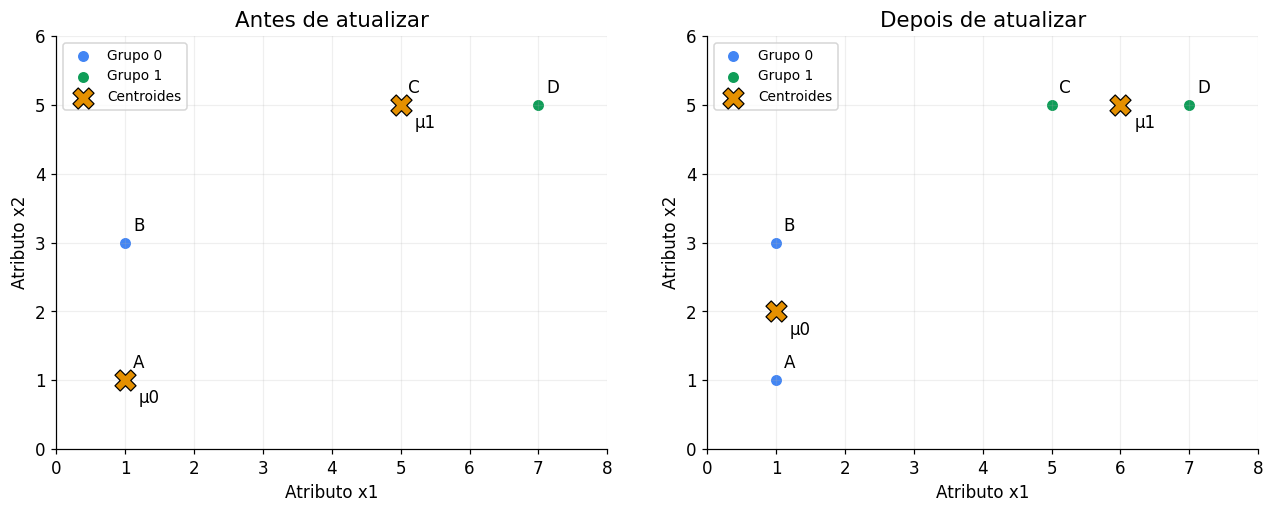

In [9]:
centros_atualizados = np.array([
    X_pequeno[rotulos_rodada == grupo].mean(axis=0)
    for grupo in range(2)
])
display(pd.DataFrame({'Grupo': [0, 1],
                      'Centroide inicial': list(map(tuple, centros_iniciais)),
                      'Centroide atualizado': list(map(tuple, centros_atualizados))}))
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
desenhar_grupos(X_pequeno, rotulos_rodada, centros_iniciais,
                'Antes de atualizar', eixos[0], nomes)
desenhar_grupos(X_pequeno, rotulos_rodada, centros_atualizados,
                'Depois de atualizar', eixos[1], nomes)
for ax in eixos:
    ax.set_xlim(0, 8)
    ax.set_ylim(0, 6)
plt.tight_layout()
plt.show()


## 7. Verificação da convergência 

Uma rodada não significa que o treinamento terminou. Precisamos verificar a atribuição com os novos centroides. Neste exemplo, ela não muda; as médias também não mudarão.


In [10]:
D_atualizada = distancias_quadradas(X_pequeno, centros_atualizados)
rotulos_novos = D_atualizada.argmin(axis=1)
tabela_verificacao = pd.DataFrame(D_atualizada, index=nomes,
                                   columns=['d² até (1, 2)', 'd² até (6, 5)'])
tabela_verificacao['Grupo'] = rotulos_novos
display(tabela_verificacao)
print('A atribuição permaneceu igual?', np.array_equal(rotulos_rodada, rotulos_novos))


A atribuição permaneceu igual? True


,"d² até (1, 2)","d² até (6, 5)",Grupo
A,1.0,41.0,0
B,1.0,29.0,0
C,25.0,1.0,1
D,45.0,1.0,1


## 8. O mesmo ajuste com scikit-learn 

Agora substituímos as etapas manuais por `KMeans`. Fixamos `init` para reproduzir o exemplo e usamos `n_init=1` porque queremos uma única inicialização.

**Atenção:** `n_init=1` não significa uma única iteração. Uma inicialização pode executar várias rodadas. `max_iter` limita o número de iterações em cada inicialização.


In [11]:
modelo_pequeno = KMeans(n_clusters=2, init=centros_iniciais.copy(),
                        n_init=1, random_state=SEMENTE)
rotulos_pequenos = modelo_pequeno.fit_predict(X_pequeno)
print('Rótulos:', rotulos_pequenos)
print('Centroides:', modelo_pequeno.cluster_centers_)
print('Inércia:', modelo_pequeno.inertia_)
print('Iterações executadas:', modelo_pequeno.n_iter_)

# Verificação das contas da aula.
np.testing.assert_array_equal(rotulos_pequenos, [0, 0, 1, 1])
np.testing.assert_allclose(modelo_pequeno.cluster_centers_, [[1, 2], [6, 5]])
assert np.isclose(modelo_pequeno.inertia_, 4.0)


Rótulos: [0 0 1 1]
Centroides: [[1. 2.]
 [6. 5.]]
Inércia: 4.0
Iterações executadas: 2


| Operação | Entrada | Saída ou efeito |
|---|---|---|
| `fit(X)` | Matriz de atributos | Ajusta o modelo e retorna o próprio estimador |
| `fit_predict(X)` | Matriz de atributos | Ajusta o modelo e retorna um rótulo por amostra |
| `predict(X_novo)` | Novas amostras com os mesmos atributos | Retorna rótulos usando os centroides existentes |
| `cluster_centers_` | Atributo após o ajuste | Matriz `(K, número de atributos)` |
| `labels_` | Atributo após o ajuste | Rótulos das amostras usadas no ajuste |
| `inertia_` | Atributo após o ajuste | Soma das distâncias² aos centroides atribuídos |

O sufixo `_` identifica, por convenção do scikit-learn, atributos aprendidos durante o ajuste.


## 9. Novas amostras com predict 

As novas amostras devem ter as mesmas colunas, na mesma ordem. `predict` não altera os centroides.

Para (2, 2), as distâncias² são 1 e 25. Para (6, 4), são 29 e 1. Esperamos os rótulos 0 e 1, respectivamente.


,x1,x2,Grupo previsto
0,2.0,2.0,0
1,6.0,4.0,1


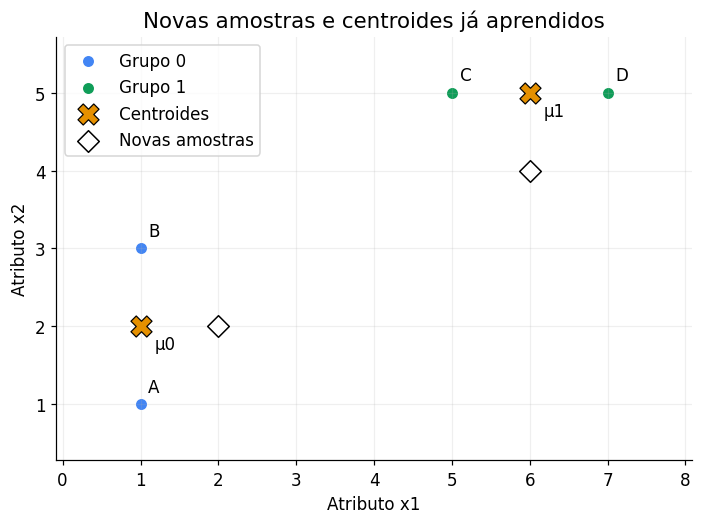

In [12]:
X_novo = np.array([[2, 2], [6, 4]], dtype=float)
centros_antes_predict = modelo_pequeno.cluster_centers_.copy()
rotulos_novos_pontos = modelo_pequeno.predict(X_novo)
resultado_novos = pd.DataFrame(X_novo, columns=['x1', 'x2'])
resultado_novos['Grupo previsto'] = rotulos_novos_pontos
display(resultado_novos)
np.testing.assert_array_equal(centros_antes_predict, modelo_pequeno.cluster_centers_)

ax = desenhar_grupos(X_pequeno, rotulos_pequenos, modelo_pequeno.cluster_centers_,
                     'Novas amostras e centroides já aprendidos', nomes=nomes)
ax.scatter(X_novo[:, 0], X_novo[:, 1], marker='D', s=100,
           c='white', edgecolors='black', label='Novas amostras', zorder=6)
ax.legend()
plt.show()


## 10. Um conjunto maior e as regiões de decisão

Vamos gerar uma base sintética com cinco concentrações de pontos. **Ela é nova: não é a base exata das imagens dos slides.** Portanto, as inércias, silhouettes e a aparência das curvas serão diferentes.

Usamos nomes distintos (`X_maior`, `modelo_maior`) para não sobrescrever o exemplo pequeno. Os rótulos usados para gerar a base não serão passados ao K-means.


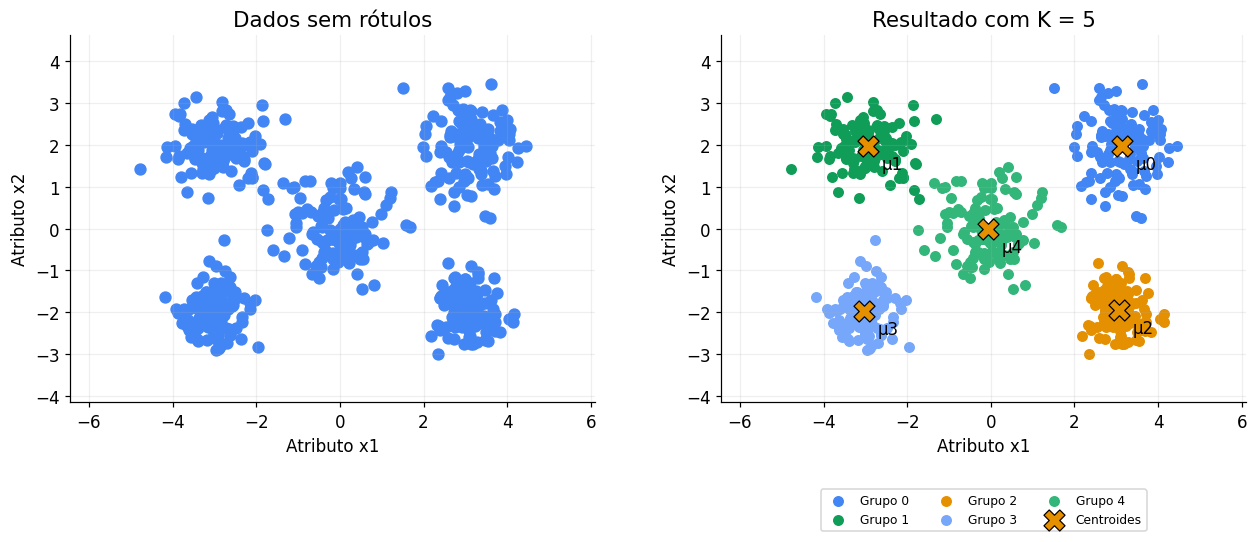

In [13]:
centros_geradores = np.array([[-3, -2], [-3, 2], [0, 0], [3, -2], [3, 2]])
X_maior, _ = make_blobs(n_samples=600, centers=centros_geradores,
                        cluster_std=[0.45, 0.55, 0.65, 0.45, 0.60],
                        random_state=SEMENTE)
modelo_maior = KMeans(n_clusters=5, init='k-means++', n_init=10,
                      random_state=SEMENTE)
rotulos_maiores = modelo_maior.fit_predict(X_maior)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
desenhar_grupos(X_maior, titulo='Dados sem rótulos', ax=eixos[0])
desenhar_grupos(X_maior, rotulos_maiores, modelo_maior.cluster_centers_,
                'Resultado com K = 5', eixos[1])
plt.tight_layout()
plt.show()


Uma região de decisão reúne as posições que recebem o mesmo grupo. Vamos preencher o plano com uma malha de pontos e chamar `predict` sobre essa malha. Isso não retreina o modelo.


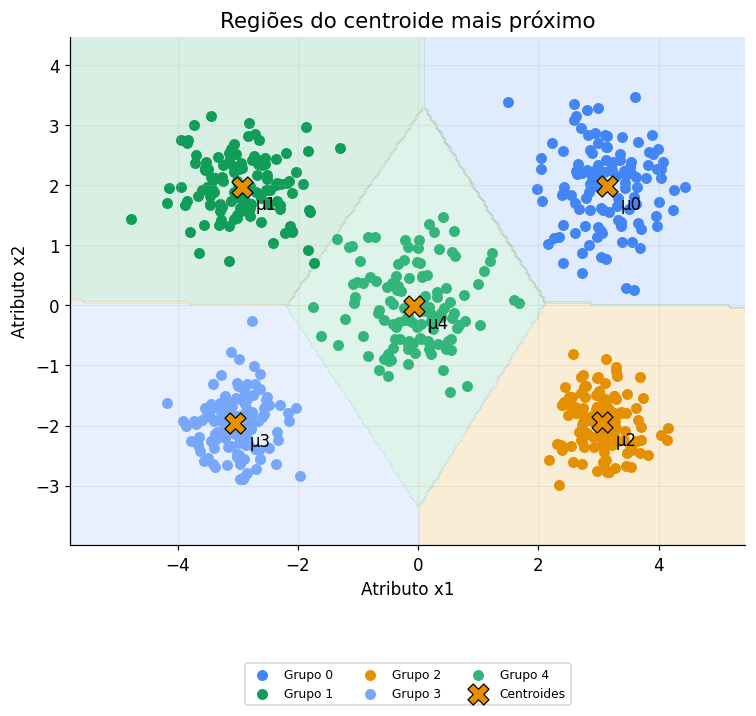

In [14]:
x_min, y_min = X_maior.min(axis=0) - 1
x_max, y_max = X_maior.max(axis=0) + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 240),
                     np.linspace(y_min, y_max, 180))
malha = np.column_stack([xx.ravel(), yy.ravel()])
regioes = modelo_maior.predict(malha).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(9, 6))
ax.contourf(xx, yy, regioes, levels=np.arange(6)-0.5,
            cmap=ListedColormap(PALETA[:5]), alpha=0.16)
desenhar_grupos(X_maior, rotulos_maiores, modelo_maior.cluster_centers_,
                'Regiões do centroide mais próximo', ax)
plt.show()


## 11. Acompanhando várias rodadas 

A função didática abaixo repete atribuição e atualização. Ela guarda o histórico para podermos observar a evolução.

Para um grupo vazio, mantemos seu centroide anterior. Essa é uma escolha simples para a aula; não reproduz todos os detalhes internos do scikit-learn. Em aplicações, prefira a implementação da biblioteca.


In [15]:
def kmeans_didatico(X, centros, max_iter=20, tolerancia=1e-6):
    centros = np.asarray(centros, dtype=float).copy()
    historico = []
    for rodada in range(1, max_iter + 1):
        distancias = distancias_quadradas(X, centros)
        rotulos = distancias.argmin(axis=1)
        novos_centros = centros.copy()
        for grupo in range(len(centros)):
            pontos = X[rotulos == grupo]
            if len(pontos) > 0:
                novos_centros[grupo] = pontos.mean(axis=0)
        inercia_atualizada = np.sum((X - novos_centros[rotulos])**2)
        historico.append({'rodada': rodada, 'antes': centros.copy(),
                          'depois': novos_centros.copy(), 'rotulos': rotulos.copy(),
                          'inercia': float(inercia_atualizada)})
        deslocamento = np.linalg.norm(novos_centros - centros)
        centros = novos_centros
        if deslocamento <= tolerancia:
            break
    return centros, historico

rng = np.random.default_rng(SEMENTE)
inicio_maior = X_maior[rng.choice(len(X_maior), size=5, replace=False)]
centros_manual_maior, historico = kmeans_didatico(X_maior, inicio_maior)
display(pd.DataFrame([{'rodada': h['rodada'], 'inércia após atualização': h['inercia']}
                      for h in historico]))


,rodada,inércia após atualização
0,1,1087.671390
1,2,1023.842165
2,3,997.395807
3,4,961.625470
4,5,853.347842
5,6,555.984176
6,7,355.895088
7,8,349.491237
8,9,349.491237


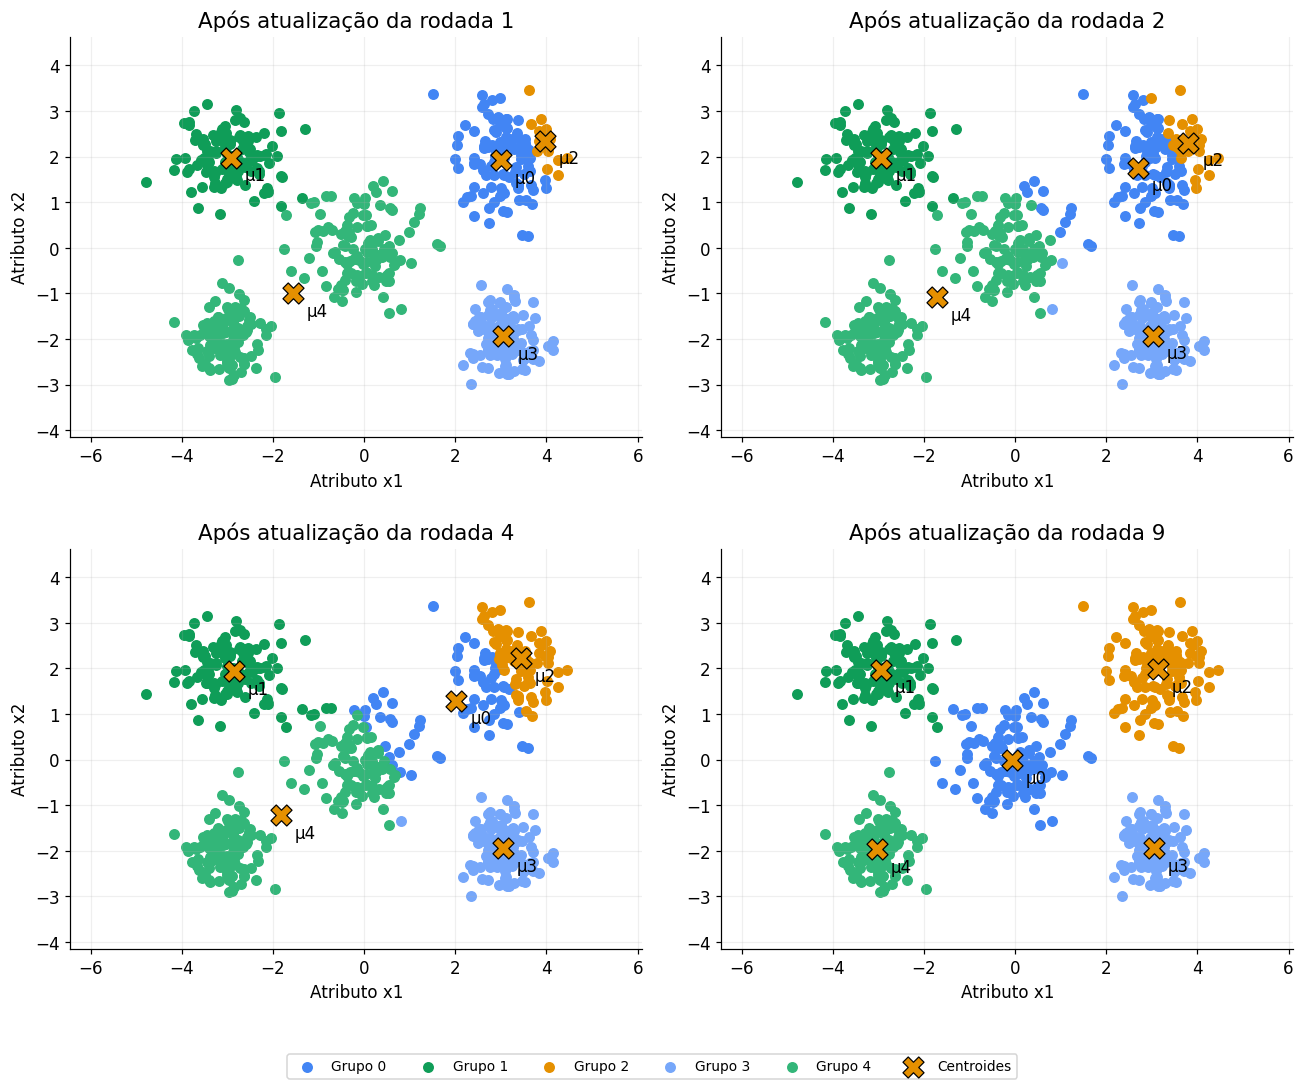

In [16]:
indices = list(dict.fromkeys([0, min(1, len(historico)-1),
                              min(3, len(historico)-1), len(historico)-1]))
fig, eixos = plt.subplots(2, 2, figsize=(12, 10), squeeze=False)
for ax, indice in zip(eixos.ravel(), indices):
    h = historico[indice]
    desenhar_grupos(X_maior, h['rotulos'], h['depois'],
                    f"Após atualização da rodada {h['rodada']}", ax)
handles, labels = eixos[0, 0].get_legend_handles_labels()
for ax in eixos.ravel():
    if ax.get_legend() is not None:
        ax.get_legend().remove()
for ax in eixos.ravel()[len(indices):]:
    ax.set_visible(False)
fig.legend(handles, labels, loc='lower center', ncol=6, fontsize=9)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


As cores mostram a atribuição feita **antes** da atualização daquela rodada; as cruzes mostram os centroides **depois** da atualização. Na rodada seguinte, as atribuições serão recalculadas.

Observe se a inércia diminui e se o movimento dos centroides fica menor. O algoritmo parar não garante que encontrou o melhor agrupamento possível.


## 12. Inicialização e n_init 

Vamos executar o K-means várias vezes com inicialização aleatória e `n_init=1`. Depois, compararemos com `k-means++` e várias inicializações.

- `random_state` torna uma execução reproduzível no mesmo ambiente.
- `init='k-means++'` favorece centroides iniciais mais distribuídos.
- `n_init=10` executa dez inicializações e escolhe a de menor inércia entre elas.

Nenhuma dessas opções garante a solução globalmente ótima. Na comparação abaixo, também não é garantido que uma configuração vença todas as outras.


In [17]:
execucoes = []
modelos_iniciais = []
for semente in range(12):
    modelo = KMeans(n_clusters=5, init='random', n_init=1, random_state=semente)
    modelo.fit(X_maior)
    modelos_iniciais.append(modelo)
    execucoes.append({'semente': semente, 'inércia': modelo.inertia_,
                      'iterações': modelo.n_iter_})
resultados_iniciais = pd.DataFrame(execucoes)
display(resultados_iniciais.round(3))
modelo_multiplas = KMeans(n_clusters=5, init='k-means++', n_init=10,
                          random_state=SEMENTE).fit(X_maior)
print('Inércia com k-means++ e n_init=10:', round(modelo_multiplas.inertia_, 3))


Inércia com k-means++ e n_init=10: 349.491


,semente,inércia,iterações
0,0,349.491,9
1,1,1243.211,15
2,2,1257.735,7
3,3,349.491,3
4,4,349.544,4
5,5,349.491,4
6,6,349.491,5
7,7,349.491,8
8,8,1263.857,4
9,9,349.491,4


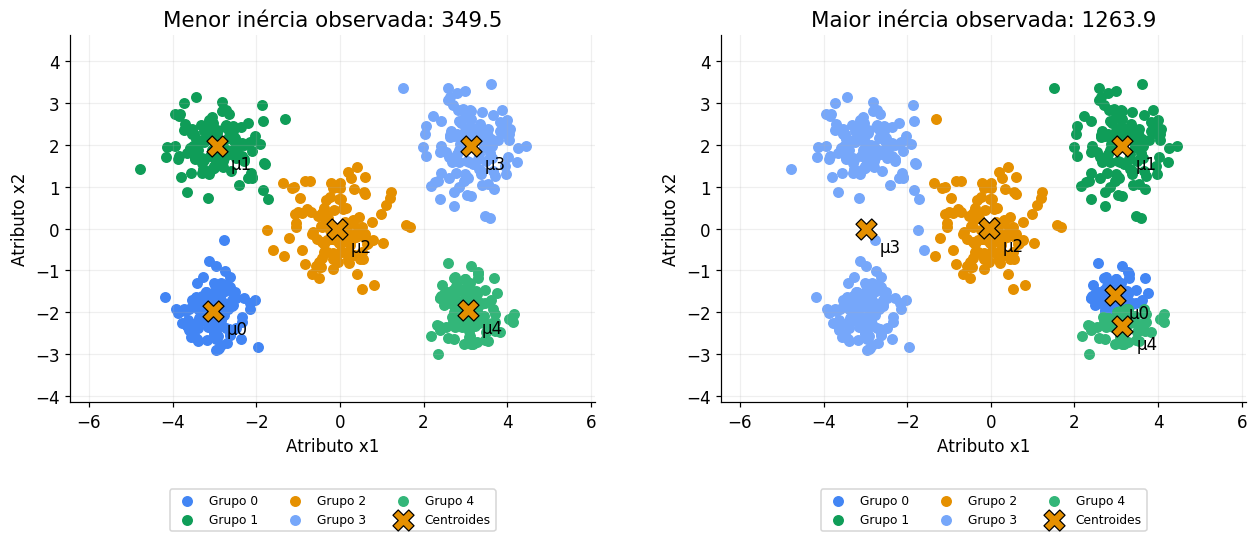

In [18]:
melhor = int(resultados_iniciais['inércia'].idxmin())
pior = int(resultados_iniciais['inércia'].idxmax())
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, indice, nome in zip(eixos, [melhor, pior], ['Menor inércia observada', 'Maior inércia observada']):
    m = modelos_iniciais[indice]
    desenhar_grupos(X_maior, m.labels_, m.cluster_centers_,
                    f'{nome}: {m.inertia_:.1f}', ax)
plt.tight_layout()
plt.show()


## 13. Escolha de K, inércia e cotovelo 

K pequeno pode fundir regiões distintas; K grande pode subdividir uma região. Comecemos comparando três escolhas nos mesmos dados.


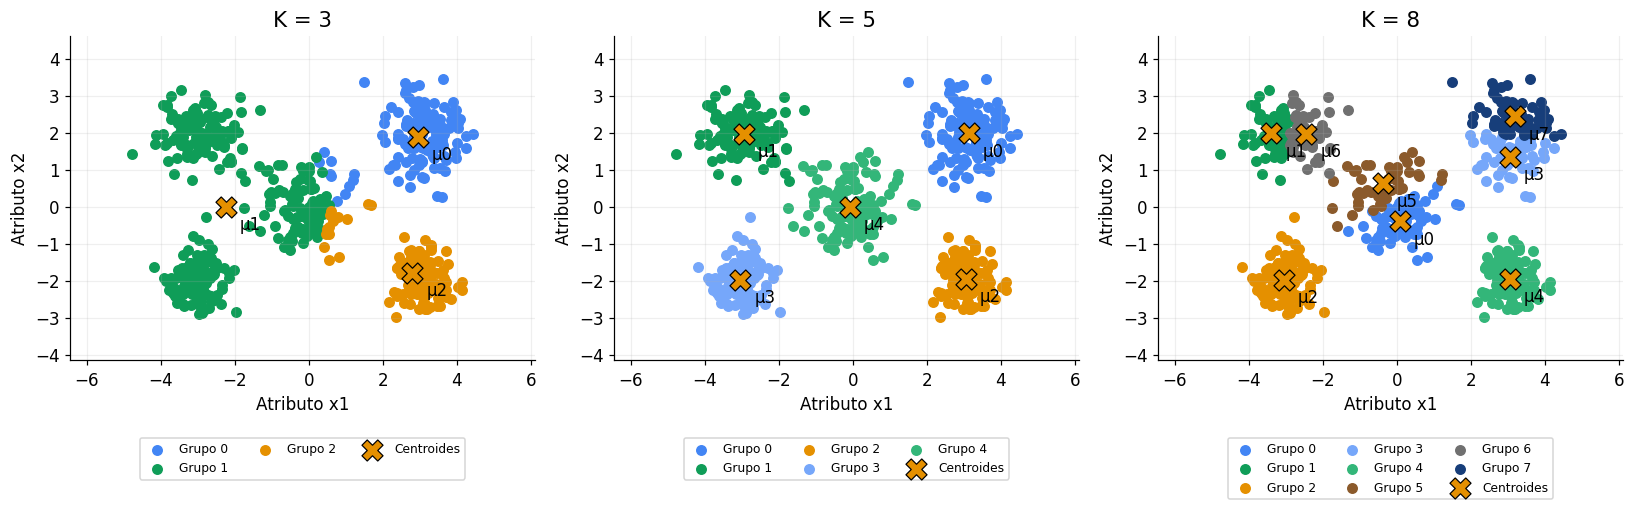

In [19]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, k in zip(eixos, [3, 5, 8]):
    m = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit(X_maior)
    desenhar_grupos(X_maior, m.labels_, m.cluster_centers_, f'K = {k}', ax)
plt.tight_layout()
plt.show()


A **inércia** soma as distâncias ao quadrado entre cada amostra e o centroide do grupo. No exemplo pequeno, cai de 8 para 4 após atualizar as médias.


In [20]:
inercia_antes = np.sum((X_pequeno - centros_iniciais[rotulos_rodada])**2)
inercia_depois = np.sum((X_pequeno - centros_atualizados[rotulos_rodada])**2)
display(pd.DataFrame({'Etapa': ['Antes da atualização', 'Depois da atualização'],
                      'Inércia': [inercia_antes, inercia_depois]}))


,Etapa,Inércia
0,Antes da atualização,8.0
1,Depois da atualização,4.0


A melhor inércia possível não aumenta quando K cresce. Em ajustes práticos, resultados locais ruins podem produzir irregularidades. Por isso, usamos várias inicializações e não escolhemos K apenas pelo menor valor de inércia.

No método do cotovelo, buscamos uma mudança de ritmo: a partir de certo K, acrescentar grupos reduz muito menos a inércia. A escolha pode ser ambígua.


,K,Inércia,Silhouette
0,1,6656.9171,NaN
1,2,2793.6671,0.5043
2,3,1903.3676,0.5403
3,4,1042.9736,0.5898
4,5,349.4912,0.7154
5,6,312.6139,0.6522
6,7,280.8672,0.5822
7,8,251.8468,0.5148
8,9,232.9683,0.5001


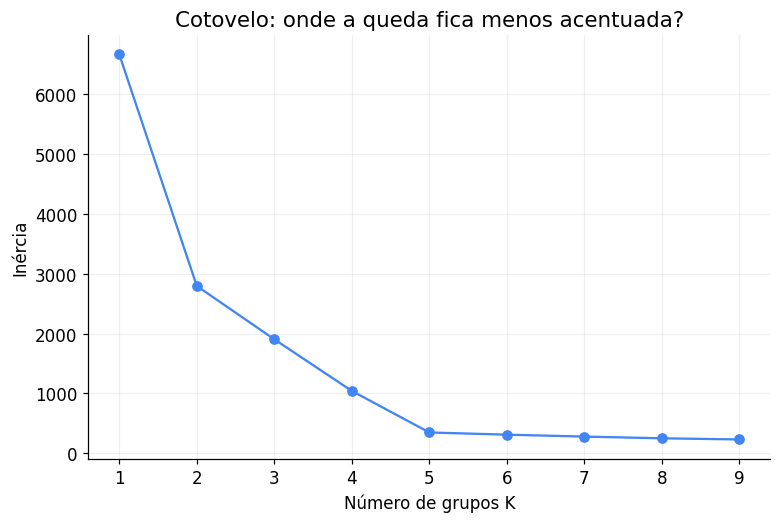

In [21]:
modelos_por_k = {}
comparacao = []
for k in range(1, 10):
    m = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit(X_maior)
    modelos_por_k[k] = m
    # Silhouette requer pelo menos dois grupos e menos grupos que amostras.
    n_grupos = len(np.unique(m.labels_))
    sil = silhouette_score(X_maior, m.labels_) if 2 <= n_grupos < len(X_maior) else np.nan
    comparacao.append({'K': k, 'Inércia': m.inertia_, 'Silhouette': sil})
comparacao_k = pd.DataFrame(comparacao)
display(comparacao_k.round(4))
plt.plot(comparacao_k['K'], comparacao_k['Inércia'], 'o-', color=AZUL)
plt.xticks(comparacao_k['K'])
plt.xlabel('Número de grupos K')
plt.ylabel('Inércia')
plt.title('Cotovelo: onde a queda fica menos acentuada?')
plt.show()


## 14. Silhouette

Silhouette combina proximidade dentro do grupo e separação em relação aos outros. Para cada amostra, compara a distância média aos demais pontos do próprio grupo com a menor distância média a outro grupo.

| Resultado | Leitura |
|---|---|
| Próximo de +1 | Boa separação em relação aos outros grupos |
| Próximo de 0 | Ponto próximo da fronteira entre grupos |
| Negativo | Ponto pode estar mais próximo de outro grupo |

`silhouette_score(X, rotulos)` retorna a **média** dos coeficientes individuais. Ele usa distâncias entre amostras, não apenas distâncias aos centroides. No scikit-learn, um grupo com uma única amostra recebe coeficiente individual zero.


Silhouette do exemplo de quatro pontos: 0.657061
Maior silhouette entre os valores testados: 5


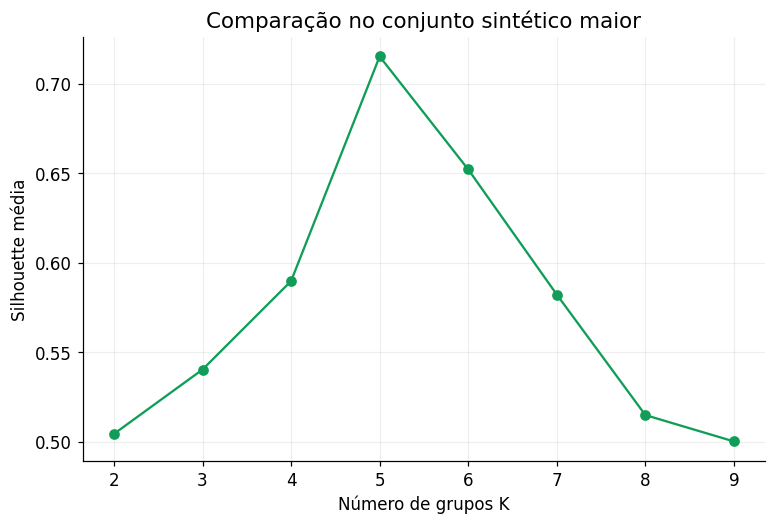

In [22]:
sil_pequeno = silhouette_score(X_pequeno, rotulos_pequenos)
print(f'Silhouette do exemplo de quatro pontos: {sil_pequeno:.6f}')
assert np.isclose(sil_pequeno, 0.6570611562376927)

validos = comparacao_k.dropna(subset=['Silhouette'])
plt.plot(validos['K'], validos['Silhouette'], 'o-', color=VERDE)
plt.xticks(validos['K'])
plt.xlabel('Número de grupos K')
plt.ylabel('Silhouette média')
plt.title('Comparação no conjunto sintético maior')
plt.show()
print('Maior silhouette entre os valores testados:',
      int(validos.loc[validos['Silhouette'].idxmax(), 'K']))


**Interpretação:** use a curva como evidência, junto com o gráfico dos grupos e o objetivo da análise. A figura dos slides favorecia K próximo de 4 ou 5; este notebook usa uma base maior diferente e pode favorecer outra escolha.

A média pode esconder grupos ou amostras problemáticos. Vamos examinar os coeficientes individuais do modelo com K = 5.


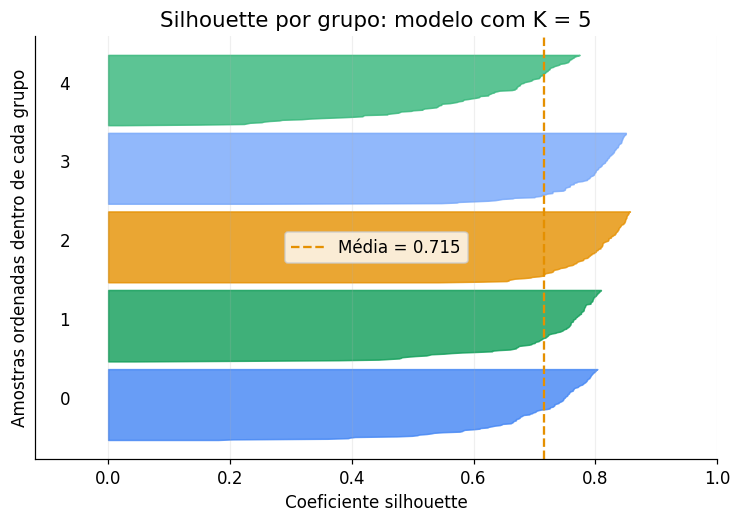

In [23]:
coeficientes = silhouette_samples(X_maior, rotulos_maiores)
fig, ax = plt.subplots(figsize=(8, 5))
inicio = 0
for grupo in np.unique(rotulos_maiores):
    valores = np.sort(coeficientes[rotulos_maiores == grupo])
    posicoes = np.arange(inicio, inicio + len(valores))
    ax.fill_betweenx(posicoes, 0, valores, color=PALETA[grupo], alpha=0.8)
    ax.text(-0.08, inicio + len(valores)/2, str(grupo))
    inicio += len(valores) + 12
ax.axvline(coeficientes.mean(), color=LARANJA, linestyle='--',
           label=f'Média = {coeficientes.mean():.3f}')
ax.set(xlabel='Coeficiente silhouette', ylabel='Amostras ordenadas dentro de cada grupo',
       title='Silhouette por grupo: modelo com K = 5', xlim=(-0.12, 1))
ax.set_yticks([])
ax.legend()
plt.show()


## 15. Experimento adicional: mudar a unidade de um atributo — slide 26

Vamos representar a segunda coluna do mesmo conjunto em uma unidade 100 vezes maior. A informação é a mesma, mas a geometria percebida pelo K-means muda.

Comparamos o agrupamento sem padronização e com `StandardScaler`. Para facilitar a leitura, os dois resultados serão desenhados nas coordenadas originais.


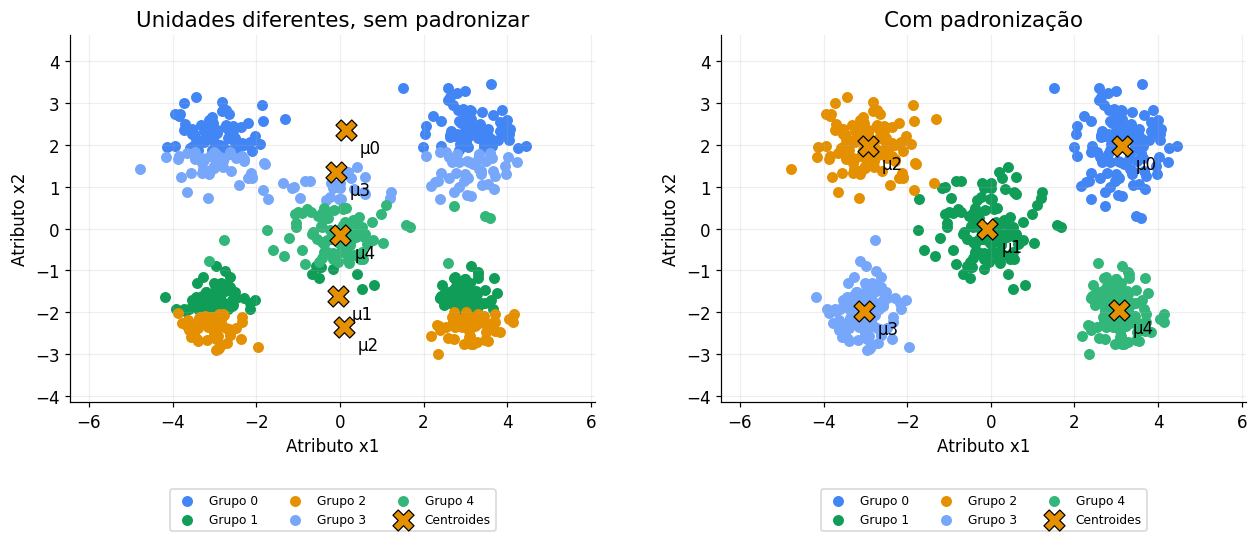

In [24]:
X_unidades = X_maior.copy()
X_unidades[:, 1] *= 100

modelo_sem_escala = KMeans(n_clusters=5, n_init=10, random_state=SEMENTE).fit(X_unidades)
escalador_maior = StandardScaler()
X_padronizado = escalador_maior.fit_transform(X_unidades)
modelo_com_escala = KMeans(n_clusters=5, n_init=10, random_state=SEMENTE).fit(X_padronizado)

# Converter centroides de volta às coordenadas originais apenas para desenhar.
centros_sem = modelo_sem_escala.cluster_centers_ / np.array([1, 100])
centros_com = escalador_maior.inverse_transform(modelo_com_escala.cluster_centers_)
centros_com = centros_com / np.array([1, 100])
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
desenhar_grupos(X_maior, modelo_sem_escala.labels_, centros_sem,
                'Unidades diferentes, sem padronizar', eixos[0])
desenhar_grupos(X_maior, modelo_com_escala.labels_, centros_com,
                'Com padronização', eixos[1])
plt.tight_layout()
plt.show()


Não compare diretamente as inércias desses dois modelos: elas foram calculadas em escalas diferentes.

Para novas amostras, use **o escalador já ajustado**. Chamar `fit_transform` nas novas amostras criaria outra transformação. Uma `Pipeline` pode encadear o escalador e o K-means e evitar esse erro, mas aqui deixamos as etapas explícitas para fins didáticos.


In [25]:
novos_nas_unidades = np.array([[0, 0], [3, 200]], dtype=float)
novos_padronizados = escalador_maior.transform(novos_nas_unidades)
print('Grupos previstos:', modelo_com_escala.predict(novos_padronizados))


Grupos previstos: [1 0]


## 16. Limitação: grupos curvos — slide 26

K-means funciona bem quando a distância aos centroides descreve grupos compactos. Para mostrar uma limitação, vamos criar duas meias-luas. Embora visualmente reconheçamos duas curvas, o K-means pode separá-las de outra forma.

Conhecer K não basta para garantir um agrupamento adequado. Para outras geometrias, pode ser necessário outro método, como DBSCAN ou agrupamento espectral; eles também exigem escolhas e avaliação próprias.


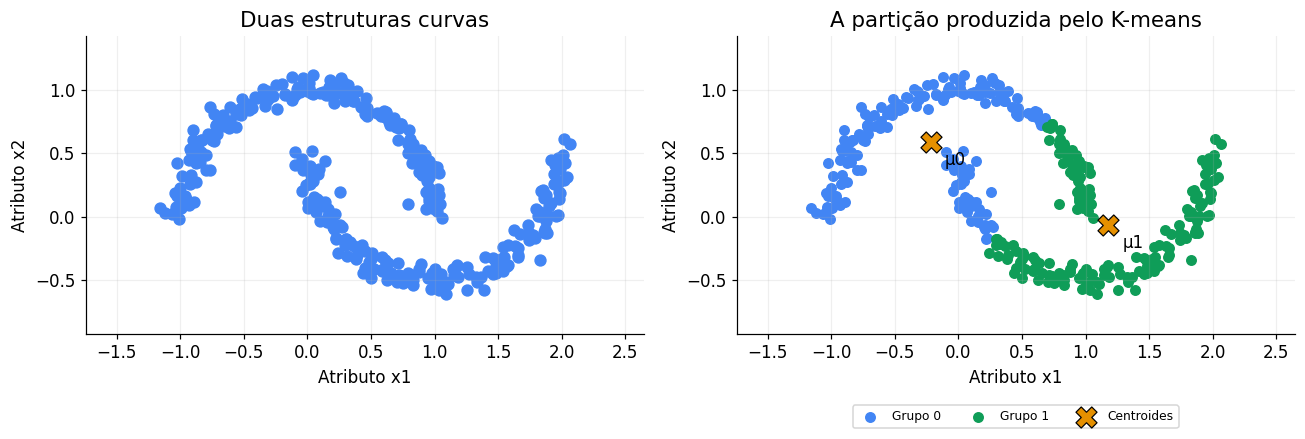

In [26]:
X_luas, _ = make_moons(n_samples=350, noise=0.06, random_state=SEMENTE)
modelo_luas = KMeans(n_clusters=2, n_init=10, random_state=SEMENTE).fit(X_luas)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
desenhar_grupos(X_luas, titulo='Duas estruturas curvas', ax=eixos[0])
desenhar_grupos(X_luas, modelo_luas.labels_, modelo_luas.cluster_centers_,
                'A partição produzida pelo K-means', eixos[1])
plt.tight_layout()
plt.show()


## 17. Exercícios

Tente responder antes de abrir a seção de soluções.

1. Com μ₀ = (1, 2) e μ₁ = (6, 5), calcule as distâncias² de (6, 4). Qual é o grupo?
2. Execute `predict` e confira se os centroides mudaram. Como isso difere de `fit_predict`?
3. No exemplo de quatro pontos, use K = 3. A inércia diminuiu? Isso basta para preferir três grupos?
4. Troque os centroides iniciais por A e B. Inspecione as rodadas e explique se o resultado final mudou.
5. No conjunto maior, teste K = 4, 5 e 6. Compare inércia, silhouette e interpretação visual.
6. Aumente `noise` no exemplo das meias-luas. O algoritmo passa a representar melhor a ideia de duas curvas?

Você pode editar a célula abaixo. As soluções usam outros nomes para preservar os resultados anteriores.


In [27]:
# Espaço para experimentar.
# Exemplo: modelo_teste = KMeans(n_clusters=3, n_init=10, random_state=42)
# rotulos_teste = modelo_teste.fit_predict(X_pequeno)


## 18. Soluções comentadas

**1 e 2.** As distâncias² de (6, 4) são 29 e 1, portanto o grupo é 1. `predict` apenas aplica os centroides existentes. `fit_predict` ajusta o modelo usando os dados que recebe e retorna os rótulos desse ajuste.


In [28]:
ponto_exercicio = np.array([[6, 4]], dtype=float)
print('Distâncias²:', distancias_quadradas(ponto_exercicio, modelo_pequeno.cluster_centers_))
print('Grupo:', modelo_pequeno.predict(ponto_exercicio))


Distâncias²: [[29.  1.]]
Grupo: [1]


**3.** Um grupo extra tende a reduzir a inércia, mas pode criar grupos com uma única amostra. Em apenas quatro pontos, o exercício serve para entender o comportamento das métricas, não para tirar conclusões estatísticas robustas.


In [29]:
solucao_k = []
for k in [2, 3]:
    m_solucao = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit(X_pequeno)
    solucao_k.append({'K': k, 'Inércia': m_solucao.inertia_,
                      'Silhouette': silhouette_score(X_pequeno, m_solucao.labels_),
                      'Tamanhos dos grupos': np.bincount(m_solucao.labels_, minlength=k).tolist()})
display(pd.DataFrame(solucao_k).round(4))


,K,Inércia,Silhouette,Tamanhos dos grupos
0,2,4.0,0.6571,"[2, 2]"
1,3,2.0,0.3091,"[1, 2, 1]"


**4.** Inicializar em A e B começa com os dois centroides perto um do outro. Acompanhe como a média do grupo maior se desloca. Compare a composição dos grupos, não apenas seus números: rótulos podem ser permutados.


In [30]:
centros_AB, historico_AB = kmeans_didatico(X_pequeno, X_pequeno[[0, 1]])
display(pd.DataFrame([{'Rodada': h['rodada'],
                       'Centroide 0': tuple(h['depois'][0]),
                       'Centroide 1': tuple(h['depois'][1]),
                       'Inércia': h['inercia']} for h in historico_AB]))


,Rodada,Centroide 0,Centroide 1,Inércia
0,1,"(1.0, 1.0)","(4.333333333333333, 4.333333333333333)",21.333333
1,2,"(1.0, 2.0)","(6.0, 5.0)",4.000000
2,3,"(1.0, 2.0)","(6.0, 5.0)",4.000000


**5.** Compare as três linhas abaixo e retome os gráficos. Um K com bom valor médio ainda pode gerar um grupo pouco útil para a aplicação.

**6.** Aumentar o ruído não resolve a inadequação entre a geometria das curvas e a representação por centroides. Observe o resultado, mas não confunda a partição encontrada com as estruturas que você pretendia identificar.


In [31]:
display(comparacao_k[comparacao_k['K'].isin([4, 5, 6])].round(4))


,K,Inércia,Silhouette
3,4,1042.9736,0.5898
4,5,349.4912,0.7154
5,6,312.6139,0.6522
